# 7. CNN with EEI at 25 angles: χ = −60° to 60°, step 5°

This test answers the reviewer's question on a dense sampling of the angle axis. In the manuscript, the 25-angle network fits the test pseudo-wells best but gives the poorest result at Well 9P: the field EEI at every angle is a combination of only two traces (AVO intercept and gradient), whereas the synthetic EEI is not, and the network learns small differences between angles that do not exist in the field data. The last part of this notebook summarises all the angle tests and runs the noise test.

This is one of the tests of manuscript Table 5. The regression network is trained **with the
same settings, the same seed (0) and the same pseudo-wells** as in notebook 02; only the EEI
angles of the input change. The EEI of the pseudo-wells is recomputed at the new angles
(`CNN_libs/eei_angles.py`); the properties and facies are those of `training_data/`. Only the
regression network is trained.

**Run time:** about 30 minutes on one NVIDIA H100 GPU.

**Outputs:** `Notebooks/outputs/CNN/training_data_eei25/` and `Notebooks/outputs/CNN/ablation_eei25/`.

In [1]:
%matplotlib inline
import json, shutil, time
import numpy as np
from IPython.display import Markdown, display
from nb_utils import *

environment()

NAME = "eei25"
CHIS = list(np.arange(-60.0, 60.1, 5.0))
TD = CNN_OUT / f"training_data_{NAME}"
RUN = CNN_OUT / f"ablation_{NAME}"
print("EEI angles:", ", ".join(f"{c:g}°" for c in CHIS))

Python 3.12.0, numpy 2.2.6


PyTorch 2.8.0+cu128, GPU: NVIDIA H100 80GB HBM3
CPU cores: 16
Package root: Stochastic_Inv_Code_Release/
Well 9P logs: not distributed (blind-well comparison skipped)
EEI angles: -60°, -55°, -50°, -45°, -40°, -35°, -30°, -25°, -20°, -15°, -10°, -5°, 0°, 5°, 10°, 15°, 20°, 25°, 30°, 35°, 40°, 45°, 50°, 55°, 60°


## Training set at the new angles

The 100,000 pseudo-wells of notebook 02 are used. If they do not exist yet, they are generated
here with the same seed, which gives the same pseudo-wells.

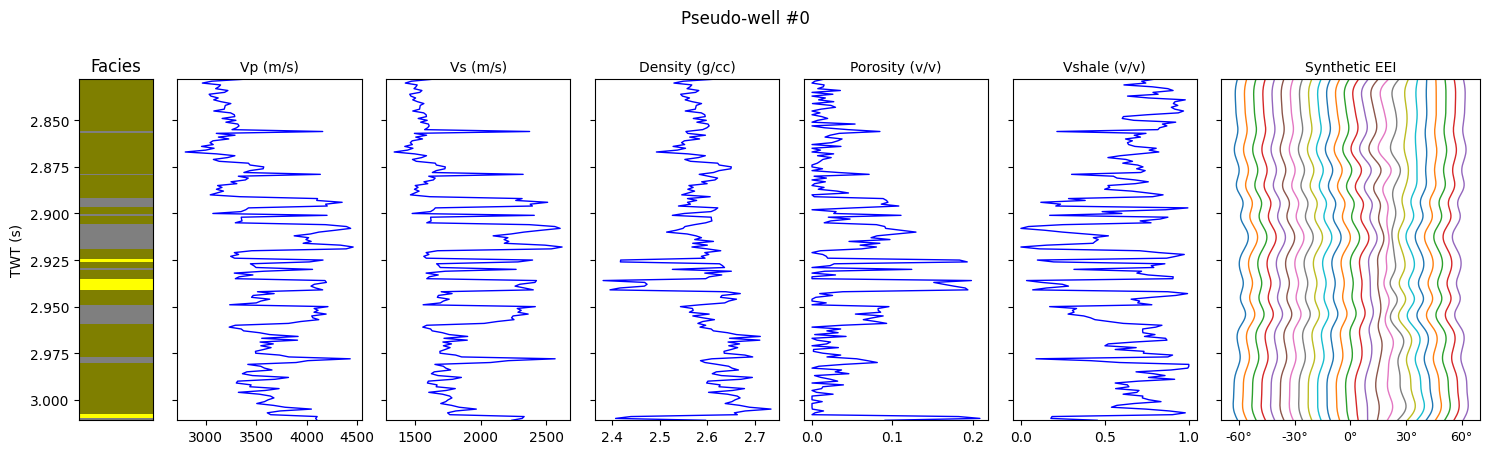

Facies fractions over the training set: shale 71.7%, silt 11.4%, sand 14.4%, calcareous sand 2.5%


In [2]:
if not (TRAIN_DIR / "eei.npy").exists():
    run("make_datamat.py", "--outdir", TRAIN_DIR, "--n", "100000", "--format", "npy",
        log=CNN_OUT / "training_data.log")
if not (TD / "eei.npy").exists():
    run("eei_angles.py", "--train-dir", TRAIN_DIR, "--outdir", TD, "--chis", *CHIS, log=RUN / "import.log")
plot_pseudowells(TD, idx=(0,))

## Field data at these angles

In [3]:
plot_field_eei(CHIS)

## Regression network

In [4]:
if not (RUN / "model.pt").exists():
    run("train_cnn.py", "--train-dir", TD, "--outdir", RUN, "--seed", 0, *REG_ARGS, log=RUN / "train.log", tail=10)
else:
    print("network exists:", RUN.relative_to(ROOT))
plot_history(RUN, title=f"Regression CNN, EEI at {len(CHIS)} angle(s)")

network exists: Notebooks/outputs/CNN/ablation_eei25


Median correlation on the 10,000 test pseudo-wells, compared with the four-angle network of notebook 02:

In [5]:
rows = {f"{NAME}": test_correlations(RUN)}
if (CNN_OUT / "regression_s0" / "metrics.json").exists():
    rows["four angles (notebook 02)"] = test_correlations(CNN_OUT / "regression_s0")
for r in rows.values():
    r["mean"] = float(np.mean([r[p] for p in PROPS]))
table(rows, list(PROPS) + ["mean"], index_name="test pseudo-wells")

| test pseudo-wells | vp | vs | rho | poro | vshale | mean |
|---|---|---|---|---|---|---|
| eei25 | 0.868 | 0.869 | 0.843 | 0.819 | 0.792 | 0.838 |
| four angles (notebook 02) | 0.835 | 0.839 | 0.817 | 0.796 | 0.768 | 0.811 |

## Application to the field line (100 MC Dropout passes)

$ python CNN_libs/infer_cnn.py --run Notebooks/outputs/CNN/ablation_eei25 --field-mode stretch --mc 100 --tag eei25 --outdir Notebooks/outputs/CNN/ablation_eei25/field


  ...
  inference: 100 MC-dropout passes in 0.55 s (input preparation 1.1 s)
  wrote SEG-Y and cnn_eei25.npz to Notebooks/outputs/CNN/ablation_eei25/field/
  wrote sections_eei25.png
[8 s, full log: Notebooks/outputs/CNN/ablation_eei25/infer.log]
$ python ODiSI_libs/make_paper_figures.py --input-dir Notebooks/outputs/CNN/ablation_eei25/field --tag eei25 --run-name eei25 --outdir Notebooks/outputs/CNN/ablation_eei25/figures --formats png --dpi 120


  ...
    Data/well9p_data.mat not found — Figure 3 shows the inversion only, no well logs or correlations
    wrote Well_9p_elasto_petrophysics_eei25.png
[3 s, full log: Notebooks/outputs/CNN/ablation_eei25/figures.log]


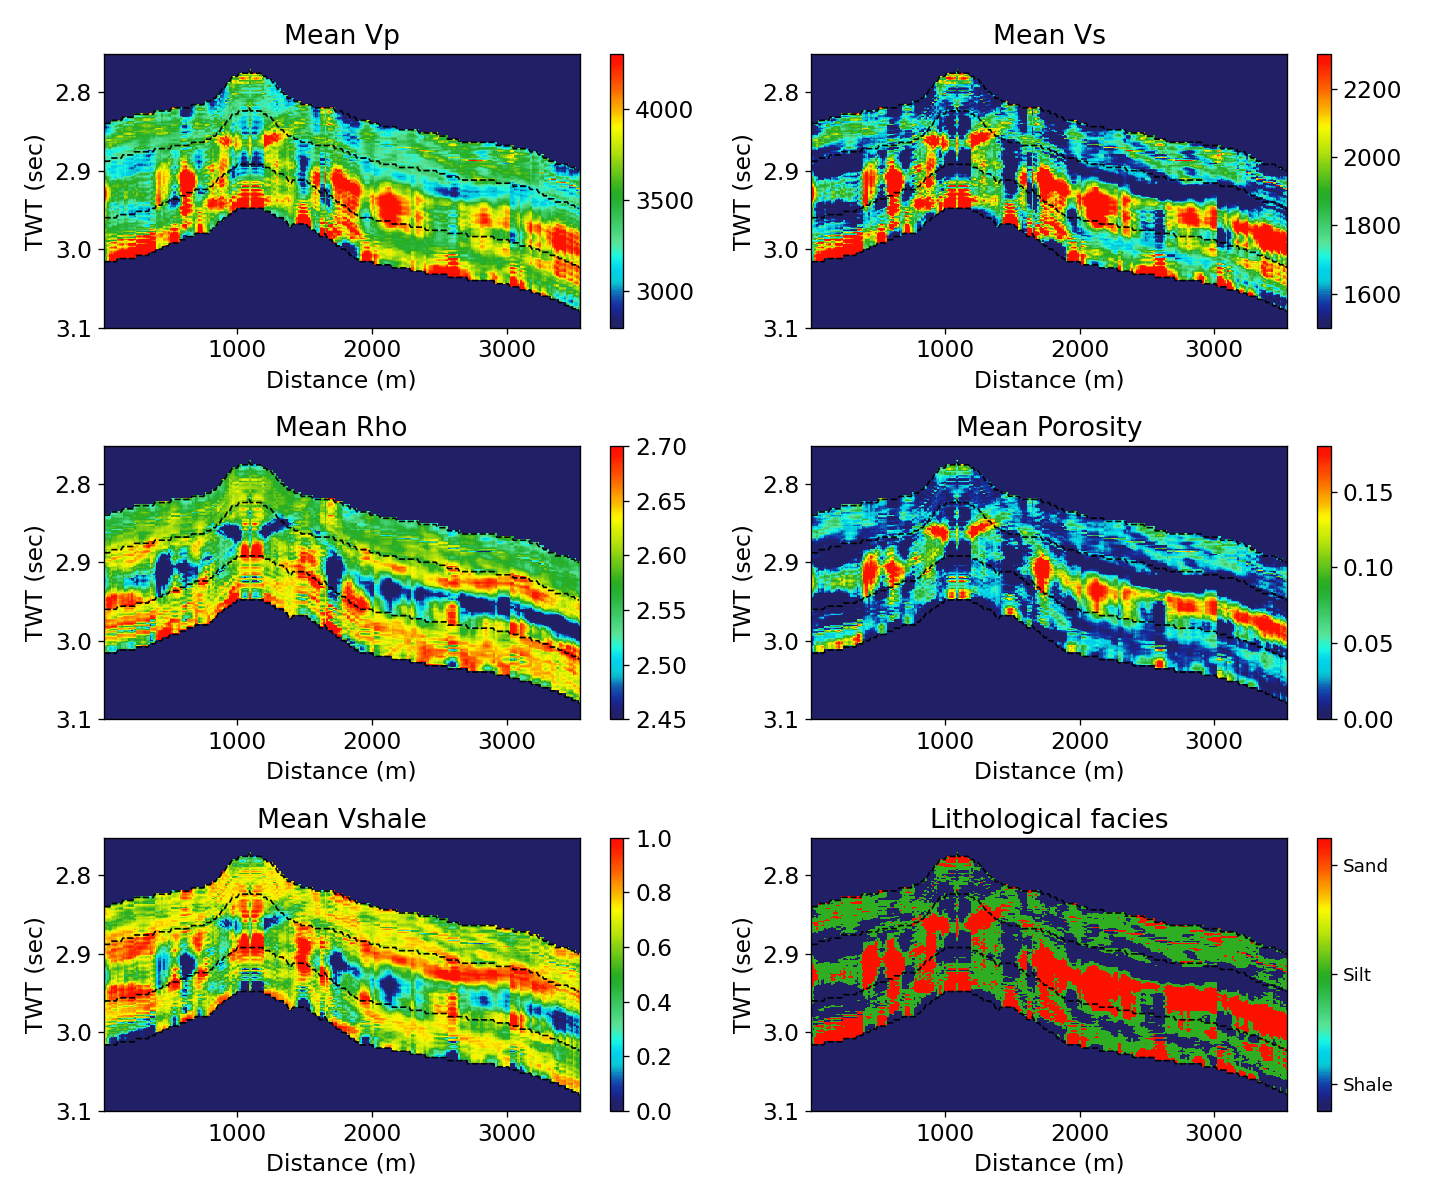

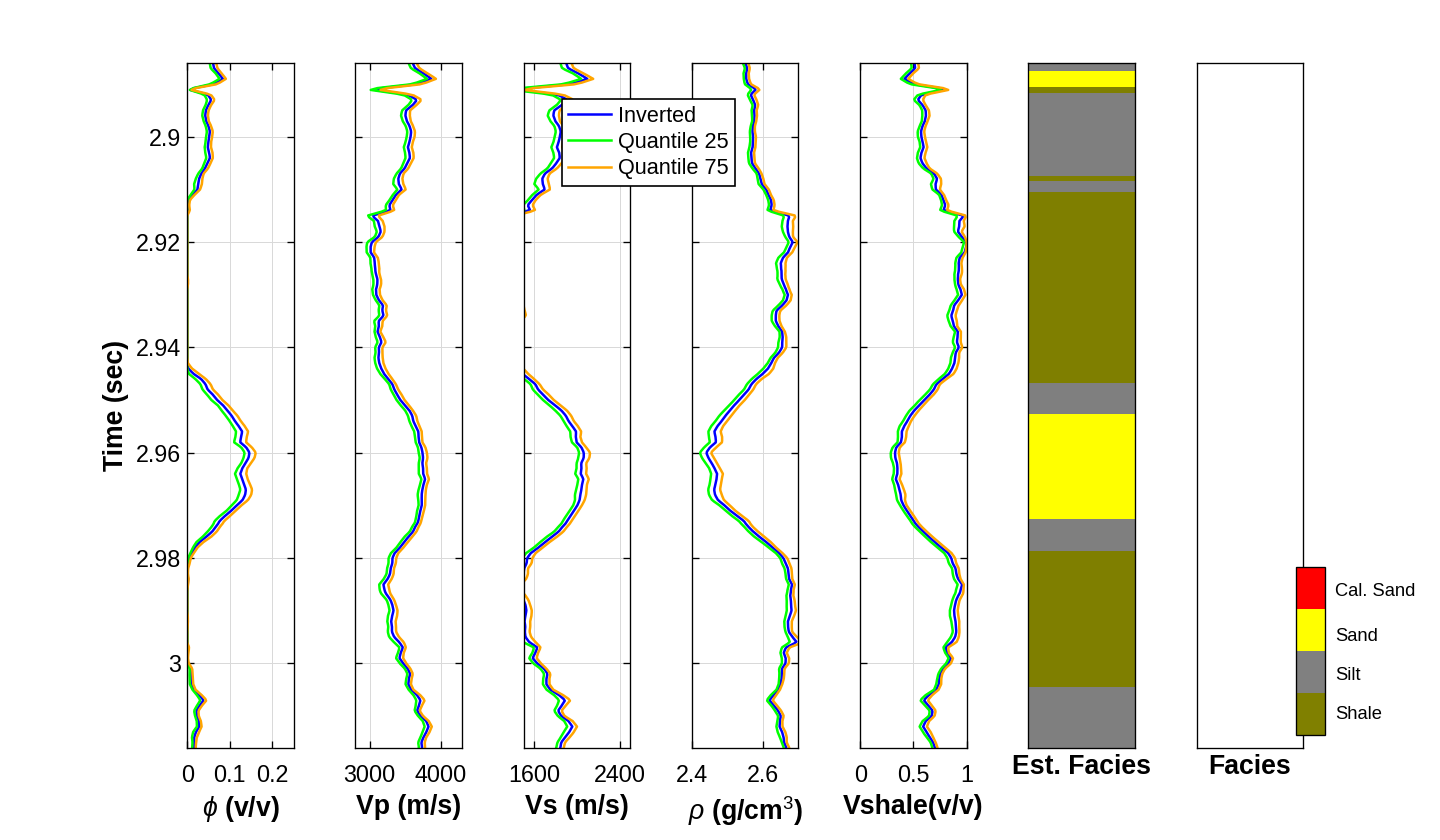

In [6]:
run("infer_cnn.py", "--run", RUN, "--field-mode", "stretch", "--mc", "100", "--tag", NAME,
    "--outdir", RUN / "field", log=RUN / "infer.log", tail=3)
run("make_paper_figures.py", "--input-dir", RUN / "field", "--tag", NAME, "--run-name", NAME,
    "--outdir", RUN / "figures", "--formats", "png", "--dpi", "120", log=RUN / "figures.log", tail=2)
show(first(RUN / "figures", "Stochastic_inversion_*.png"))
show(first(RUN / "figures", "Well_9p_elasto_petrophysics_*.png"), width=900)

## Blind well

Correlation coefficients at Well 9P in the manuscript (Table 5):

| EEI angles | Vp | Vs | ρ | Vshale | φ | mean |
|---|---|---|---|---|---|---|
| this test | 0.523 | 0.614 | 0.679 | 0.651 | 0.647 | 0.623 |
| four angles | 0.699 | 0.780 | 0.704 | 0.731 | 0.674 | 0.718 |

In [7]:
r = read_well_correlation(RUN / "figures" / f"well_correlation_{NAME}.txt")
if r:
    table({NAME: r}, list(PROPS))
else:
    print("Well 9P logs not available: blind-well correlations not computed.")

Well 9P logs not available: blind-well correlations not computed.


## Summary of the angle tests (manuscript Table 5)

This section collects the networks of notebooks 02–07 that have been run. *Test* is the mean of
the median correlations of the five properties on the 10,000 test pseudo-wells.

In [8]:
runs = {"−60°, −7.5°, 25°, 45° (02)": CNN_OUT / "regression_s0",
        "−60° (03)": CNN_OUT / "ablation_chi_m60", "−7.5° (04)": CNN_OUT / "ablation_chi_m7.5",
        "25° (05)": CNN_OUT / "ablation_chi_25", "45° (06)": CNN_OUT / "ablation_chi_45",
        "−60° to 60°, step 5° (07)": CNN_OUT / "ablation_eei25"}
paper_test = [0.811, 0.743, 0.717, 0.693, 0.76, 0.838]
rows, missing = {}, []
for (label, d), pt in zip(runs.items(), paper_test):
    if not (d / "metrics.json").exists():
        missing.append(label)
        continue
    t = test_correlations(d)
    rows[label] = {"test, this run": float(np.mean(list(t.values()))), "test, manuscript": pt}
    w = read_well_correlation(first(d / "figures", "well_correlation_*.txt"))
    if w:
        rows[label]["Well 9P mean r"] = float(np.mean([w[p] for p in PROPS]))
cols = ["test, this run", "test, manuscript"] + (["Well 9P mean r"] if any("Well 9P mean r" in r for r in rows.values()) else [])
table(rows, cols, index_name="EEI angles")
if missing:
    print("not run yet:", ", ".join(missing))

| EEI angles | test, this run | test, manuscript |
|---|---|---|
| −60°, −7.5°, 25°, 45° (02) | 0.811 | 0.811 |
| −60° (03) | 0.744 | 0.743 |
| −7.5° (04) | 0.717 | 0.717 |
| 25° (05) | 0.690 | 0.693 |
| 45° (06) | 0.759 | 0.760 |
| −60° to 60°, step 5° (07) | 0.838 | 0.838 |

### Sensitivity to noise in the AVO gradient

The field EEI at every angle is a combination of only two traces, the AVO intercept and gradient,
and the gradient is the noisier one. Here band-limited noise proportional to sin χ, with 0, 10, 25
and 50% of the rms of the gradient term, is added to the EEI of the test pseudo-wells, and the
median correlation of each network is computed again. The same noise is used for all networks.
In the manuscript, at 50% noise the median density correlation falls to 0.48 with 25 angles,
against 0.59 with four angles.

In [9]:
have = [d for d in runs.values() if (d / "model.pt").exists()]
out = CNN_OUT / "noise_sensitivity.json"
run("noise_sensitivity.py", "--runs", *have, "--ref-train-dir", TRAIN_DIR, "--out", out,
    log=CNN_OUT / "noise_sensitivity.log", tail=len(have) * 4)
res = json.loads(out.read_text())
rows = {}
for name, r in res.items():
    rows[name] = {f"ρ, noise {s}": r[s]["rho"] for s in ("0", "0.1", "0.25", "0.5")}
table(rows, list(next(iter(rows.values())).keys()), index_name="network")

$ python CNN_libs/noise_sensitivity.py --runs Notebooks/outputs/CNN/regression_s0 Notebooks/outputs/CNN/ablation_chi_m60 Notebooks/outputs/CNN/ablation_chi_m7.5 Notebooks/outputs/CNN/ablation_chi_25 Notebooks/outputs/CNN/ablation_chi_45 Notebooks/outputs/CNN/ablation_eei25 --ref-train-dir Notebooks/outputs/CNN/training_data --out Notebooks/outputs/CNN/noise_sensitivity.json


  regression_s0          noise    0: vp 0.835 vs 0.839 rho 0.817 poro 0.796 vshale 0.768
  regression_s0          noise  0.1: vp 0.827 vs 0.827 rho 0.800 poro 0.779 vshale 0.756
  regression_s0          noise 0.25: vp 0.787 vs 0.768 rho 0.724 poro 0.698 vshale 0.695
  regression_s0          noise  0.5: vp 0.699 vs 0.641 rho 0.584 poro 0.551 vshale 0.571
  ablation_chi_m60       noise    0: vp 0.794 vs 0.796 rho 0.703 poro 0.697 vshale 0.729
  ablation_chi_m60       noise  0.1: vp 0.793 vs 0.794 rho 0.702 poro 0.696 vshale 0.728
  ablation_chi_m60       noise 0.25: vp 0.784 vs 0.784 rho 0.696 poro 0.687 vshale 0.718
  ablation_chi_m60       noise  0.5: vp 0.750 vs 0.742 rho 0.675 poro 0.654 vshale 0.679
  ablation_chi_m7.5      noise    0: vp 0.785 vs 0.772 rho 0.670 poro 0.657 vshale 0.701
  ablation_chi_m7.5      noise  0.1: vp 0.785 vs 0.771 rho 0.670 poro 0.657 vshale 0.700
  ablation_chi_m7.5      noise 0.25: vp 0.783 vs 0.770 rho 0.669 poro 0.656 vshale 0.699
  ablation_chi_m7.5  

| network | ρ, noise 0 | ρ, noise 0.1 | ρ, noise 0.25 | ρ, noise 0.5 |
|---|---|---|---|---|
| regression_s0 | 0.817 | 0.800 | 0.724 | 0.584 |
| ablation_chi_m60 | 0.703 | 0.702 | 0.696 | 0.675 |
| ablation_chi_m7.5 | 0.670 | 0.670 | 0.669 | 0.666 |
| ablation_chi_25 | 0.781 | 0.760 | 0.685 | 0.572 |
| ablation_chi_45 | 0.745 | 0.738 | 0.711 | 0.647 |
| ablation_eei25 | 0.843 | 0.809 | 0.678 | 0.472 |